In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("penguins.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

   Unnamed: 0 species     island  bill_length_mm  bill_depth_mm  \
0           1  Adelie  Torgersen            39.1           18.7   
1           2  Adelie  Torgersen            39.5           17.4   
2           3  Adelie  Torgersen            40.3           18.0   
3           4  Adelie  Torgersen             NaN            NaN   
4           5  Adelie  Torgersen            36.7           19.3   

   flipper_length_mm  body_mass_g     sex  year  
0              181.0       3750.0    male  2007  
1              186.0       3800.0  female  2007  
2              195.0       3250.0  female  2007  
3                NaN          NaN     NaN  2007  
4              193.0       3450.0  female  2007  
(344, 9)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         344 non-null    int64  
 1   species            344 non-null    str    
 2 

Index(['Unnamed: 0', 'species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')
Unnamed: 0             int64
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object
Unnamed: 0            0
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64
Duplicate rows: 0
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
       Unnamed: 0  bill_length_mm  bill_depth_mm  flipper_length_mm  \
count  344.000000      342.000000     342.000000         342.000000   
mean   172.500000       43.921930      17.151170         200.915205   
std     99.448479        

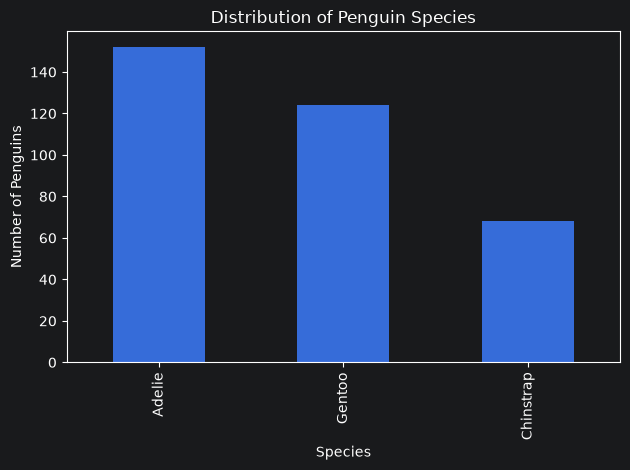

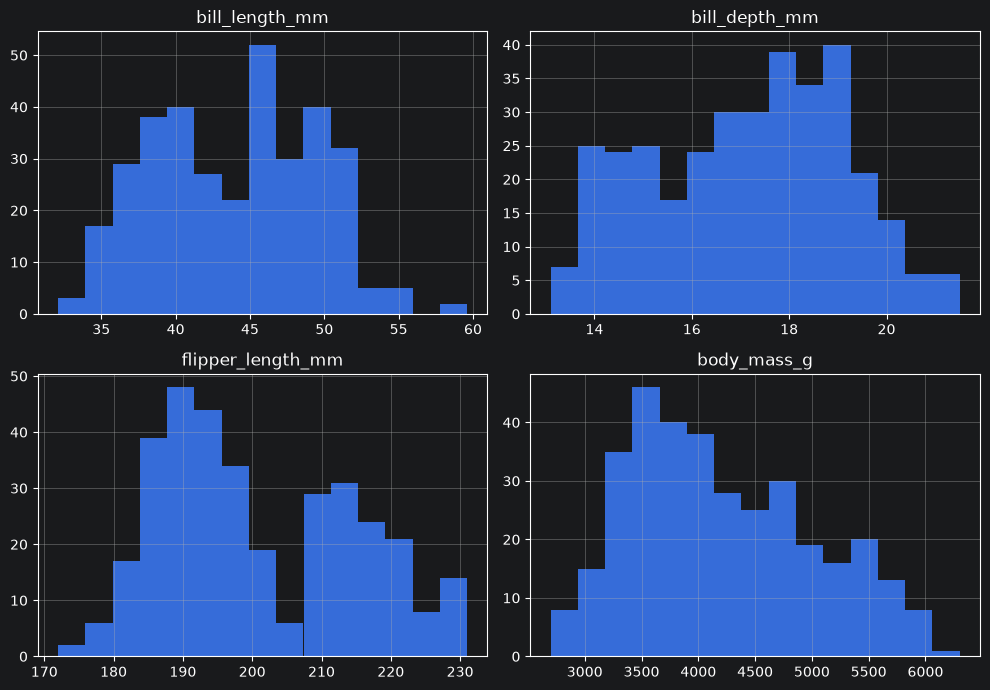

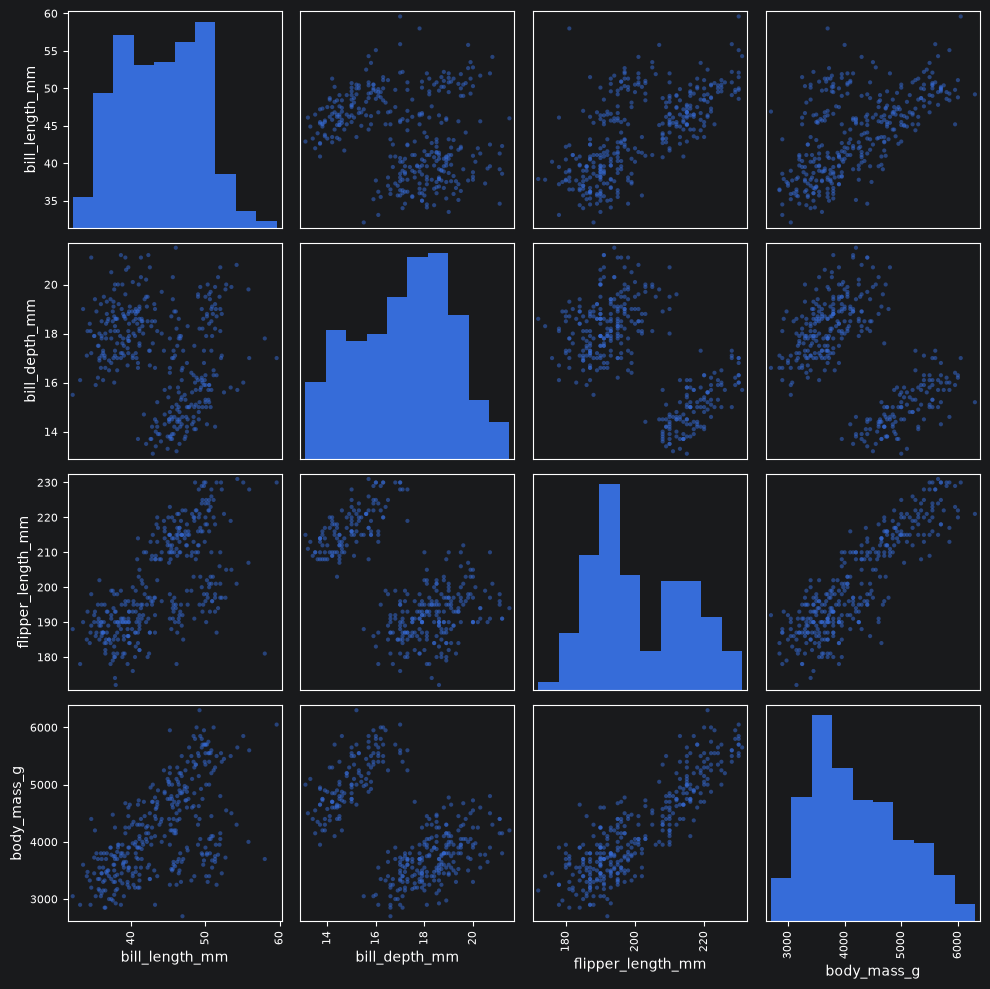

In [31]:
# Check column names and data types
print(df.columns)
print(df.dtypes)

# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Examine the distribution of species
print(df["species"].value_counts())

# Examine numerical statistics
print(df.describe())

# Plot the number of penguins in each species
df["species"].value_counts().plot(kind="bar")
plt.title("Distribution of Penguin Species")
plt.xlabel("Species")
plt.ylabel("Number of Penguins")
plt.tight_layout()
plt.show()

# Plot distributions of numerical features
df[[
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]].hist(figsize=(10, 7), bins=15)

plt.tight_layout()
plt.show()

# Examine relationships between numerical features
pd.plotting.scatter_matrix(
    df[[
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g"
    ]],
    figsize=(10, 10),
    diagonal="hist"
)

plt.tight_layout()
plt.show()

In [32]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

X = df[features]

# Replace missing measurements with column medians
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Standardize the measurements
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Prepared data shape:", X_scaled.shape)

Prepared data shape: (344, 4)


K = 2 | Silhouette Score = 0.531
K = 3 | Silhouette Score = 0.444
K = 4 | Silhouette Score = 0.398
K = 5 | Silhouette Score = 0.376
K = 6 | Silhouette Score = 0.367
K = 7 | Silhouette Score = 0.33


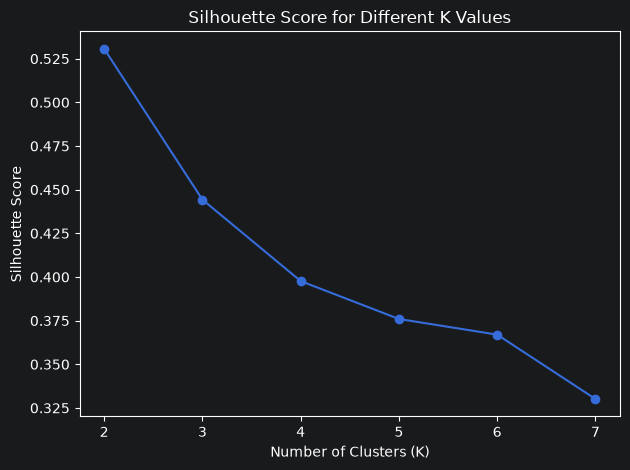

In [33]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = range(2, 8)
scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    scores.append(score)

    print("K =", k, "| Silhouette Score =", round(score, 3))

plt.plot(list(k_values), scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

In [34]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

print(df[["species", "Cluster"]])
print(df["Cluster"].value_counts().sort_index())

       species  Cluster
0       Adelie        0
1       Adelie        0
2       Adelie        0
3       Adelie        2
4       Adelie        0
..         ...      ...
339  Chinstrap        2
340  Chinstrap        2
341  Chinstrap        2
342  Chinstrap        2
343  Chinstrap        2

[344 rows x 2 columns]
Cluster
0    132
1    123
2     89
Name: count, dtype: int64


  Principal Component  Explained Variance (%)  Cumulative Variance (%)
0                 PC1                   68.84                    68.84
1                 PC2                   19.31                    88.15
2                 PC3                    9.14                    97.29
3                 PC4                    2.71                   100.00


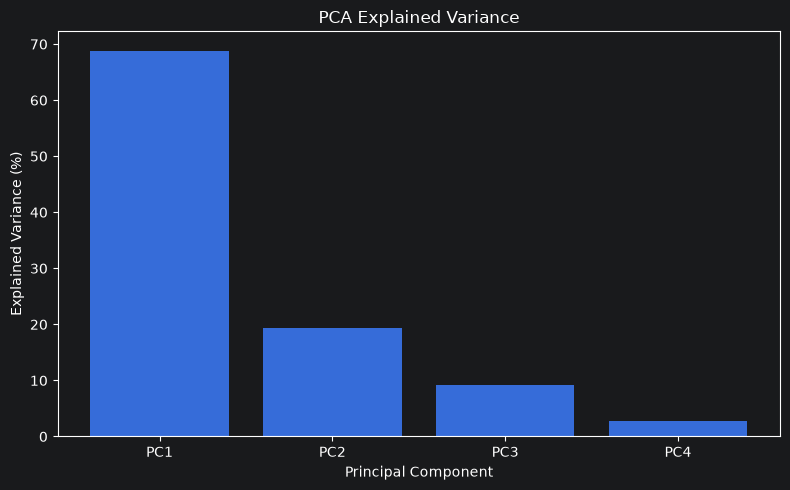

In [35]:
from sklearn.decomposition import PCA


pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_ * 100

variance_table = pd.DataFrame({
    "Principal Component": [
        "PC1", "PC2", "PC3", "PC4"
    ],
    "Explained Variance (%)": explained,
    "Cumulative Variance (%)": explained.cumsum()
})

print(variance_table.round(2))

plt.figure(figsize=(8, 5))

plt.bar(
    variance_table["Principal Component"],
    variance_table["Explained Variance (%)"]
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.tight_layout()
plt.show()

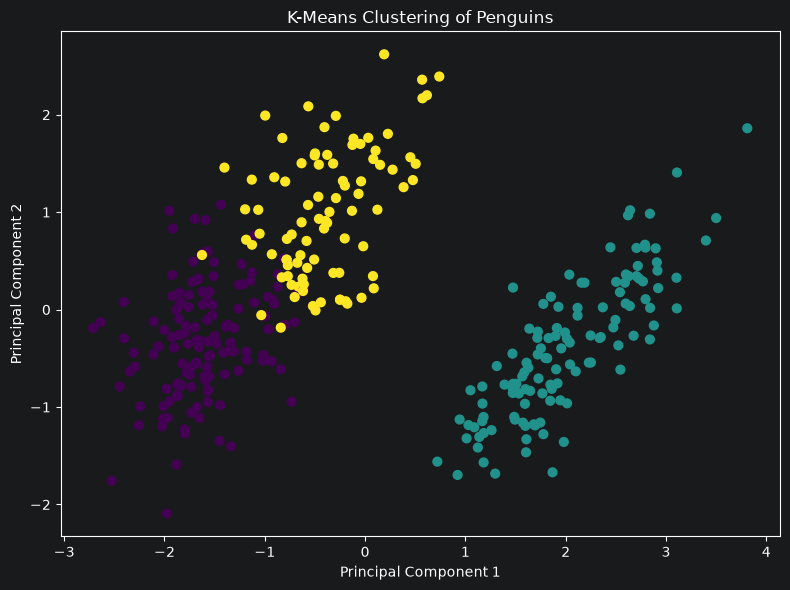

Variance explained by two components: 0.8815082383211492


In [36]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Penguins")
plt.tight_layout()
plt.show()

print(
    "Variance explained by two components:",
    pca.explained_variance_ratio_.sum()
)

In [37]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", round(score, 3))

# Compare clusters with actual species after training
print(pd.crosstab(df["species"], df["Cluster"]))

Silhouette Score: 0.444
Cluster      0    1   2
species                
Adelie     127    0  25
Chinstrap    5    0  63
Gentoo       0  123   1
